## Problem Statement

### Context

AllLife Bank is a US bank that has a growing customer base. The majority of these customers are liability customers (depositors) with varying sizes of deposits. The number of customers who are also borrowers (asset customers) is quite small, and the bank is interested in expanding this base rapidly to **bring in more loan business** and in the process, earn more through the interest on loans. In particular, the management wants to explore ways of **converting its liability customers to personal loan customers** (while retaining them as depositors).

A campaign that the bank ran last year for liability customers showed a healthy conversion rate of over 9% success. This has encouraged the retail marketing department to devise campaigns with **better target marketing** to increase the success ratio.

You as a Data scientist at AllLife bank have to build a model that will help the marketing department **to identify the potential customers who have a higher probability of purchasing the loan.**

### Objective

To predict whether a liability customer will buy personal loans, to understand which customer attributes are most significant in driving purchases, and identify which segment of customers to target more.

### Data Dictionary
* `ID`: Customer ID
* `Age`: Customer’s age in completed years
* `Experience`: #years of professional experience
* `Income`: Annual income of the customer (in thousand dollars)
* `ZIP Code`: Home Address ZIP code.
* `Family`: the Family size of the customer
* `CCAvg`: Average spending on credit cards per month (in thousand dollars)
* `Education`: Education Level. 1: Undergrad; 2: Graduate;3: Advanced/Professional
* `Mortgage`: Value of house mortgage if any. (in thousand dollars)
* `Personal_Loan`: Did this customer accept the personal loan offered in the last campaign? (0: No, 1: Yes)
* `Securities_Account`: Does the customer have securities account with the bank? (0: No, 1: Yes)
* `CD_Account`: Does the customer have a certificate of deposit (CD) account with the bank? (0: No, 1: Yes)
* `Online`: Do customers use internet banking facilities? (0: No, 1: Yes)
* `CreditCard`: Does the customer use a credit card issued by any other Bank (excluding All life Bank)? (0: No, 1: Yes)

## Importing necessary libraries

In [ ]:
# Installing the libraries with the specified version.
!pip install numpy==2.0.2 pandas==2.2.2 matplotlib==3.10.0 seaborn==0.13.2 scikit-learn==1.6.1 sklearn-pandas==2.2.0 -q --user

In [ ]:
!pip install uszipcode
!pip install sqlalchemy_mate==2.0.0.0

**Note**:

1. After running the above cell, kindly restart the notebook kernel (for Jupyter Notebook) or runtime (for Google Colab), write the relevant code for the project from the next cell, and run all cells sequentially from the next cell.

2. On executing the above line of code, you might see a warning regarding package dependencies. This error message can be ignored as the above code ensures that all necessary libraries and their dependencies are maintained to successfully execute the code in this notebook.

In [ ]:

import numpy as np
import pandas as pd
from pandas import Series
from uszipcode import SearchEngine

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.manifold import TSNE
from google.colab import drive

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import recall_score, accuracy_score, precision_score, f1_score, confusion_matrix

drive.mount('/content/drive')

RS=0
ZIPFinder = SearchEngine()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Loading the dataset

In [ ]:
dset = pd.read_csv('......./Loan_Modelling.csv')


## Data Overview

* Observations
* Sanity checks

In [ ]:
#testing the dataset
dset.head()

,ID,Age,Experience,Income,ZIPCode,Family,CCAvg,Education,Mortgage,Personal_Loan,Securities_Account,CD_Account,Online,CreditCard
0,1,25,1,49,91107,4,1.6,1,0,0,1,0,0,0
1,2,45,19,34,90089,3,1.5,1,0,0,1,0,0,0
2,3,39,15,11,94720,1,1.0,1,0,0,0,0,0,0
3,4,35,9,100,94112,1,2.7,2,0,0,0,0,0,0
4,5,35,8,45,91330,4,1.0,2,0,0,0,0,0,1


In [ ]:
# checking data type and nullable
dset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   ID                  5000 non-null   int64  
 1   Age                 5000 non-null   int64  
 2   Experience          5000 non-null   int64  
 3   Income              5000 non-null   int64  
 4   ZIPCode             5000 non-null   int64  
 5   Family              5000 non-null   int64  
 6   CCAvg               5000 non-null   float64
 7   Education           5000 non-null   int64  
 8   Mortgage            5000 non-null   int64  
 9   Personal_Loan       5000 non-null   int64  
 10  Securities_Account  5000 non-null   int64  
 11  CD_Account          5000 non-null   int64  
 12  Online              5000 non-null   int64  
 13  CreditCard          5000 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 547.0 KB


Observation:

---


- The data does not have nulls
- The Id column is not necessary for the evaluation
- We have categorical data

In [ ]:
df = dset.copy()

In [ ]:
categorical = ['Education', 'Securities_Account', 'CD_Account', 'Online', 'CreditCard']

In [ ]:

for col in categorical:
    df[col] = df[col].astype('category')
#data types after type change
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype   
---  ------              --------------  -----   
 0   ID                  5000 non-null   int64   
 1   Age                 5000 non-null   int64   
 2   Experience          5000 non-null   int64   
 3   Income              5000 non-null   int64   
 4   ZIPCode             5000 non-null   int64   
 5   Family              5000 non-null   int64   
 6   CCAvg               5000 non-null   float64 
 7   Education           5000 non-null   category
 8   Mortgage            5000 non-null   int64   
 9   Personal_Loan       5000 non-null   int64   
 10  Securities_Account  5000 non-null   category
 11  CD_Account          5000 non-null   category
 12  Online              5000 non-null   category
 13  CreditCard          5000 non-null   category
dtypes: category(5), float64(1), int64(8)
memory usage: 376.7 KB


In [ ]:
df.drop('ID', axis=1, inplace=True)

In [ ]:
#check min, max, and mean.
df.describe()

,Age,Experience,Income,ZIPCode,Family,CCAvg,Mortgage,Personal_Loan
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,45.338400,20.104600,73.774200,93169.257000,2.396400,1.937938,56.498800,0.096000
std,11.463166,11.467954,46.033729,1759.455086,1.147663,1.747659,101.713802,0.294621
min,23.000000,-3.000000,8.000000,90005.000000,1.000000,0.000000,0.000000,0.000000
25%,35.000000,10.000000,39.000000,91911.000000,1.000000,0.700000,0.000000,0.000000
50%,45.000000,20.000000,64.000000,93437.000000,2.000000,1.500000,0.000000,0.000000
75%,55.000000,30.000000,98.000000,94608.000000,3.000000,2.500000,101.000000,0.000000
max,67.000000,43.000000,224.000000,96651.000000,4.000000,10.000000,635.000000,1.000000


Observation:

---

- the min value of experience is a negative number

## Exploratory Data Analysis.

- EDA is an important part of any project involving data.
- It is important to investigate and understand the data better before building a model with it.
- A few questions have been mentioned below which will help you approach the analysis in the right manner and generate insights from the data.
- A thorough analysis of the data, in addition to the questions mentioned below, should be done.

**Questions**:

1. What is the distribution of mortgage attribute? Are there any noticeable patterns or outliers in the distribution?
2. How many customers have credit cards?
3. What are the attributes that have a strong correlation with the target attribute (personal loan)?
4. How does a customer's interest in purchasing a loan vary with their age?
5. How does a customer's interest in purchasing a loan vary with their education?



```
# This is formatted as code
```

Utility methods

---



In [ ]:
# Takes a feature and groups the data
# divide each group by the Personal_Loan and plot it
def bar_personal_load_vs_feature(feature, label_rotation = 0, dataset=df):
    # Grouping the data by the feature and calculating normalized counts (percentages)
    vs_personal_loan = dataset.groupby(feature, observed=True)['Personal_Loan'].value_counts(normalize=True).mul(100).reset_index(name='percentage')
    # showing diagram
    plot = sns.barplot(data=vs_personal_loan, x=feature, y='percentage', hue='Personal_Loan')
    if label_rotation:
        plot.set_xticklabels(plot.get_xticklabels(), rotation=label_rotation, ha="right")
    plt.ylabel('Percentage') # Set y-axis label to 'Percentage'
    plt.show()



---



In [ ]:
#checking the target variable
# group the Personal
group_personal_loan = df.groupby('Personal_Loan')
# count how many are in each group
group_personal_loan['Personal_Loan'].value_counts()


,count
Personal_Loan,
0,4520
1,480


Observations

---
We can see that the data set is not abalance and we will need to set some configuration when we create the model



<Axes: xlabel='Mortgage', ylabel='Count'>

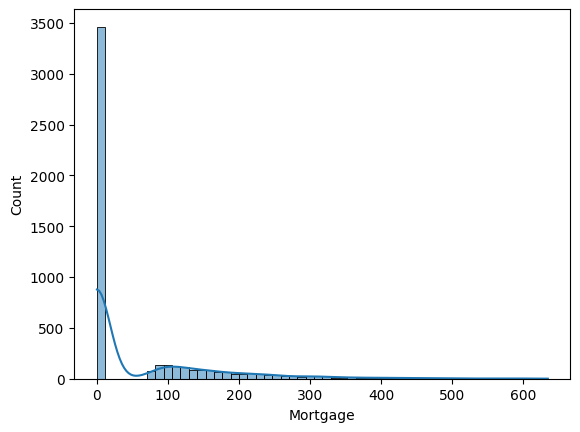

In [ ]:
sns.histplot(df['Mortgage'], kde=True)

<Axes: xlabel='Mortgage'>

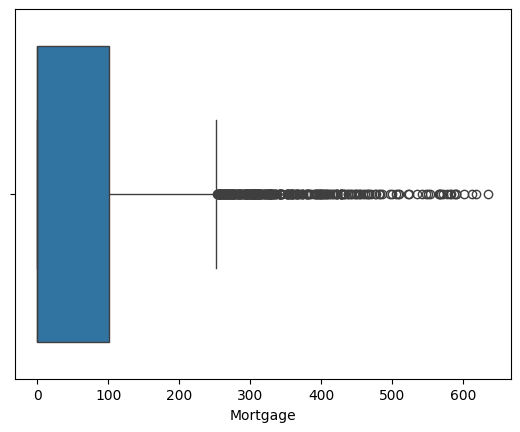

In [ ]:
sns.boxplot(x=df['Mortgage'])

Observation:

---


- Data is skewed to the right
- a lot of mortage near 0
- There are outliers.
- We can say that we have 2 groups, one with very low mortgages ( almost 0 ) and the ones with high mortgages.


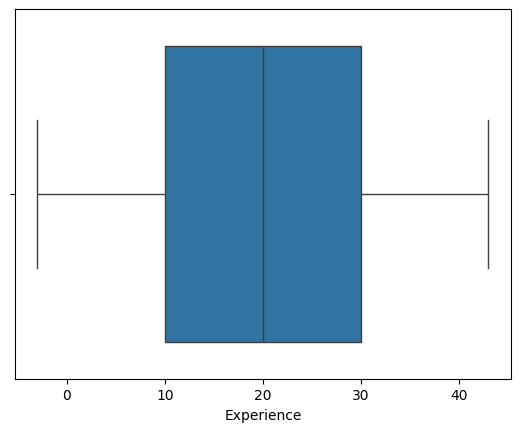

In [ ]:
sns.boxplot(x=df['Experience'])
plt.show()

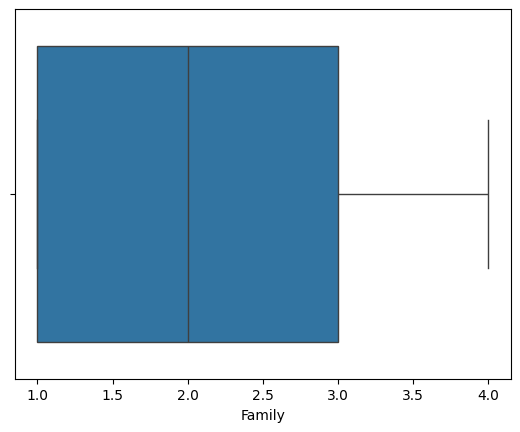

In [ ]:
sns.boxplot(x=df['Family'])
plt.show()

<Axes: xlabel='CCAvg'>

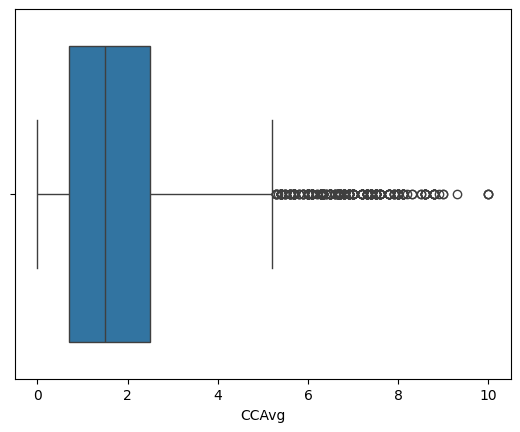

In [ ]:
sns.boxplot(x=df['CCAvg'])

<Axes: xlabel='CCAvg', ylabel='Count'>

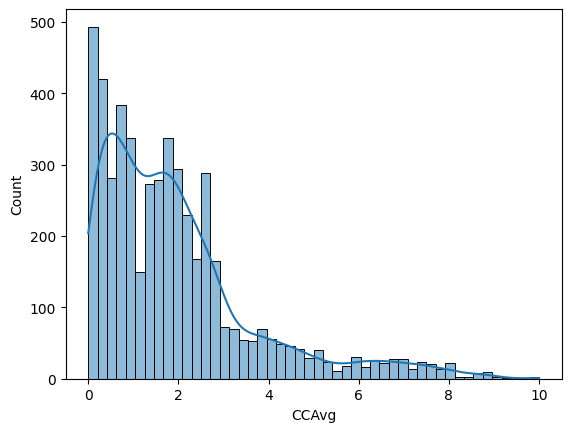

In [ ]:
sns.histplot(df['CCAvg'], kde=True)

Observation:

---


- Right skewed
- Outliners that seems like a group
- very similar with Mortage

<Axes: xlabel='Income'>

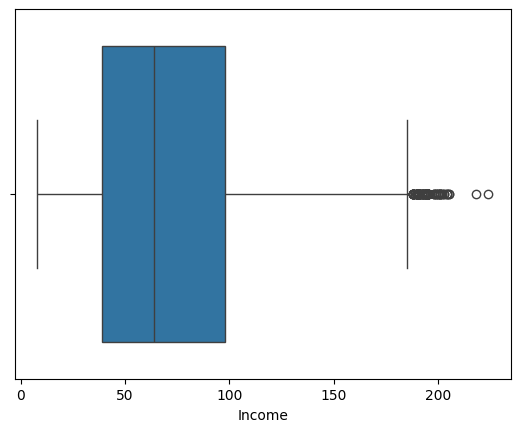

In [ ]:
sns.boxplot(x=df['Income'])

<Axes: xlabel='Age'>

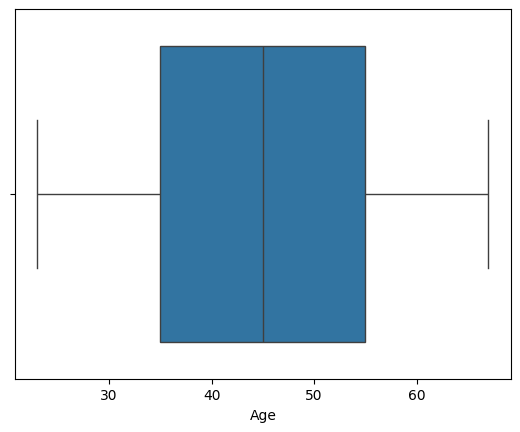

In [ ]:
sns.boxplot(x=df['Age'])

<Axes: xlabel='Age', ylabel='Count'>

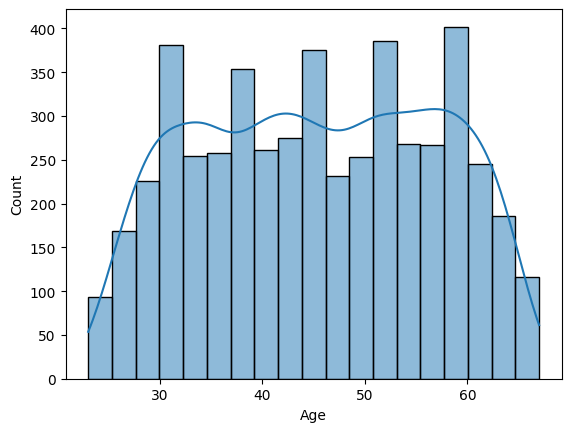

In [ ]:
sns.histplot(df['Age'], kde=True)

Observation:

---


- The Age's data is symmetric
- It looks like the Age's data is divided in 4 groups (25-35, 35-45, 45-55, 55-65).


In [ ]:
df['CreditCard'].value_counts()/len(df)

,count
CreditCard,
0,0.706
1,0.294


Observations:

---


- 70.6% does not have credit card
- 29.4% has one

In [ ]:
df['Personal_Loan'].value_counts()/len(df)

,count
Personal_Loan,
0,0.904
1,0.096


Observations:

---


- 90.4% does not have Personal loan
- 09.4% has Personal loan

<Axes: >

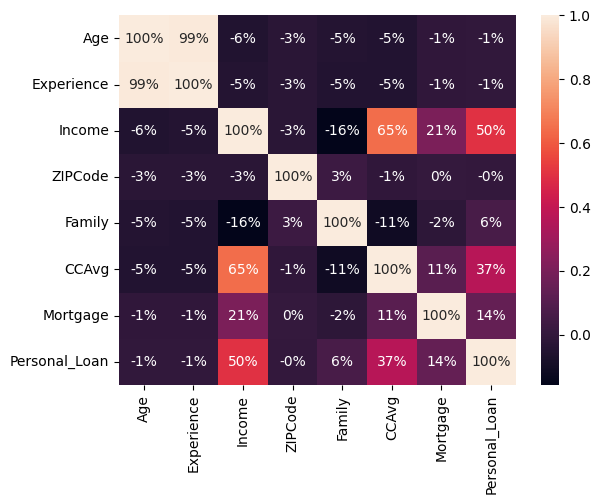

In [ ]:
numeric_cols = df.select_dtypes(include='number').corr()
sns.heatmap(numeric_cols, annot=True, fmt='.0%')

Observations

---


- The Income and the average spending on credit cards are the attributes with more correlation with personal Loan
  - Income has 50% of correlation
  - CCAvg has 37% of correlation
- The CCAvg and the Income also are verry correlated between them.
  - 65% of correlation

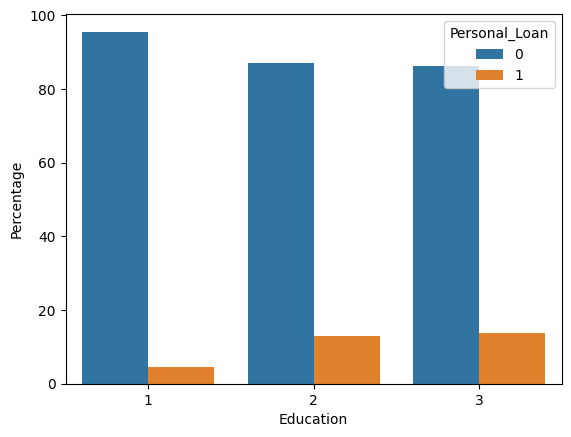

In [ ]:
# Grouping the data by education
bar_personal_load_vs_feature('Education')

Observation:

---


- The group of people with higher education has more Personal loads.
- We can see from the data that lower levels of education are associated with a lower percentage of personal loans.

/tmp/ipython-input-405562836.py:9: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  plot.set_xticklabels(plot.get_xticklabels(), rotation=label_rotation, ha="right")


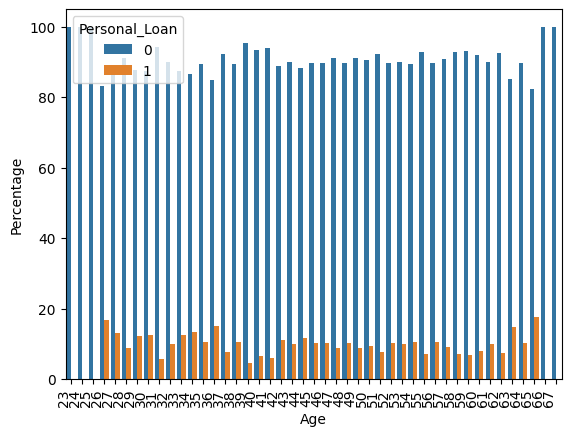

In [ ]:
bar_personal_load_vs_feature('Age', 90)

Observations:


---


-   It seems that some ages have more loans, but it does not seems like it is linear.







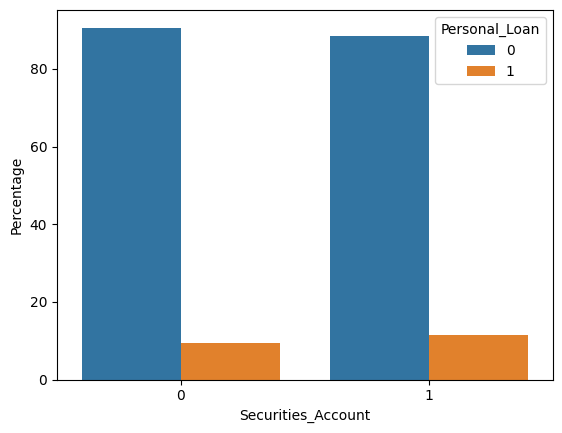

In [ ]:
bar_personal_load_vs_feature('Securities_Account')

Observation

---


*   people without security account have more Loans




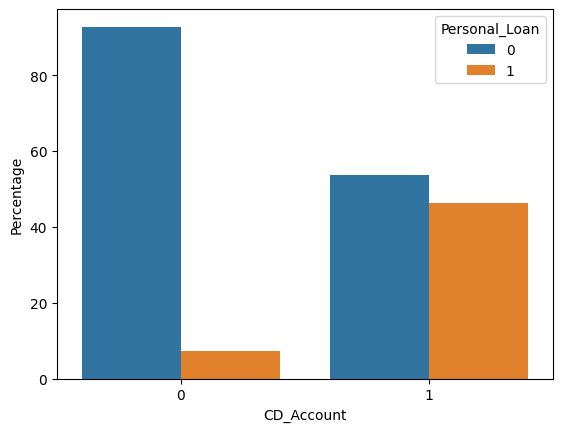

In [ ]:
bar_personal_load_vs_feature('CD_Account')

Observations:

---


*   Seems like having a CD Account is increasing the probablilty of having a Personal Loan




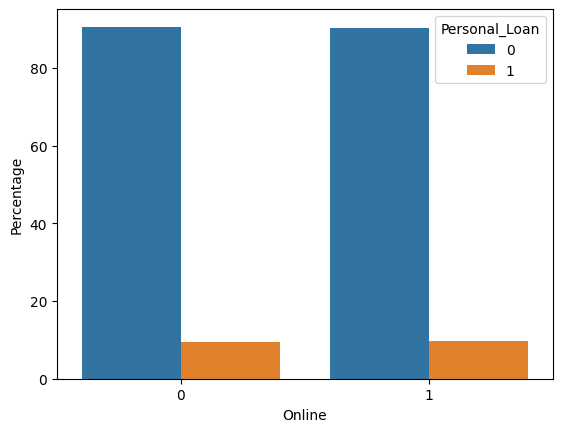

In [ ]:
bar_personal_load_vs_feature('Online')

Observation:

---
- The Online feature does not have a strong relationship.



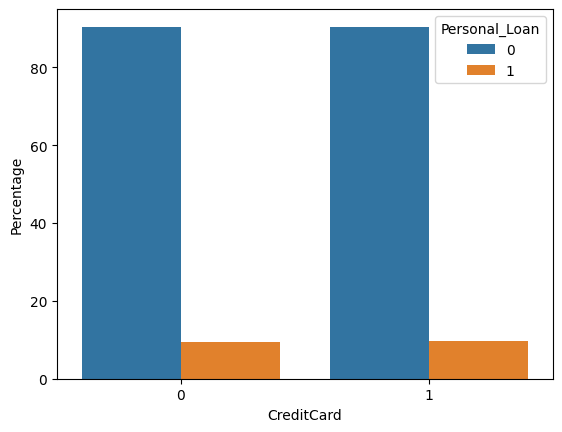

In [ ]:
bar_personal_load_vs_feature('CreditCard')

Observation:

---
- the credit card seems not to be a strong corelation with Personal Loan


<Figure size 1000x800 with 0 Axes>

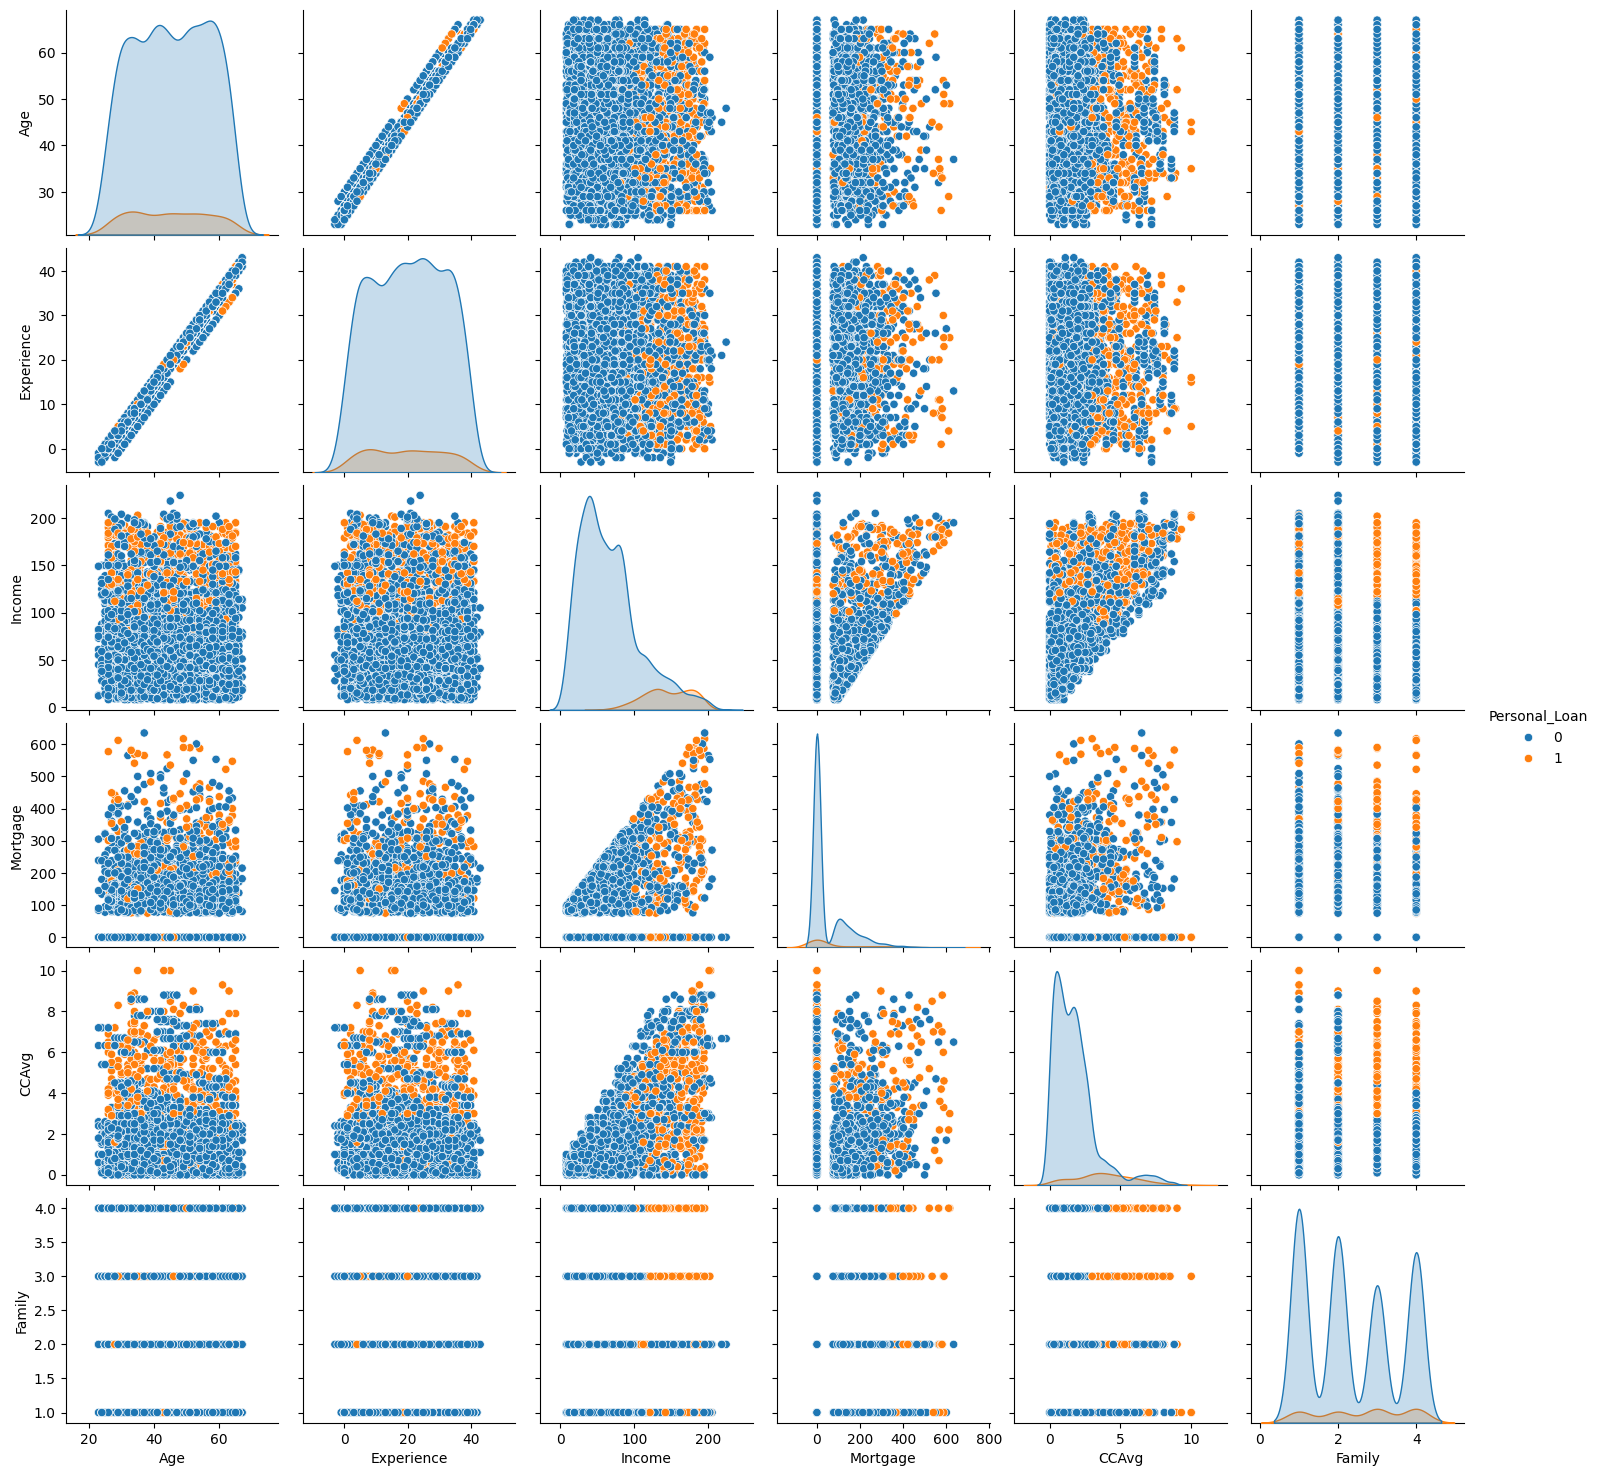

In [ ]:
plt.figure(figsize=(10, 8))
vars = ['Age', 'Experience', 'Income', 'Mortgage', 'CCAvg', 'Family']
sns.pairplot(df,vars=vars, hue='Personal_Loan', diag_kind='kde');

## Data Preprocessing

* Missing value treatment
* Feature engineering (if needed)
* Outlier detection and treatment (if needed)
* Preparing data for modeling
* Any other preprocessing steps (if needed)

In [ ]:
# check if there is negative experience
df[df['Experience']<0].head()

,Age,Experience,Income,ZIPCode,Family,CCAvg,Education,Mortgage,Personal_Loan,Securities_Account,CD_Account,Online,CreditCard
89,25,-1,113,94303,4,2.30,3,0,0,0,0,0,1
226,24,-1,39,94085,2,1.70,2,0,0,0,0,0,0
315,24,-2,51,90630,3,0.30,3,0,0,0,0,1,0
451,28,-2,48,94132,2,1.75,3,89,0,0,0,1,0
524,24,-1,75,93014,4,0.20,1,0,0,0,0,1,0


Observation:
- we have multiple negative numbers in Experiences we need to change them

In [ ]:
# replacing the negative number with positive version of them
df['Experience'] = df['Experience'].apply(lambda x: abs(x))
#checking we do not have negative experience
df[df['Experience']<0]

,Age,Experience,Income,ZIPCode,Family,CCAvg,Education,Mortgage,Personal_Loan,Securities_Account,CD_Account,Online,CreditCard


In [ ]:
# getting the city name from ZIP code

df['ZIPCode'] = df['ZIPCode'].astype(str)
print(len(df['ZIPCode'].unique()))
code = df['ZIPCode'].apply(lambda x: ZIPFinder.by_zipcode(x))

# create the column city with the name of the city.
df['City'] = code.apply(lambda x: x.major_city if x else None)


467


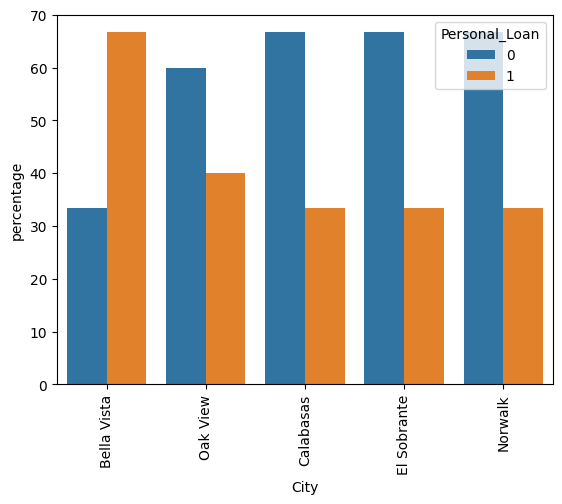

In [ ]:
# showing multivariat analicis
group_by_city = df.groupby('City')['Personal_Loan'].value_counts(normalize=True).mul(100).reset_index(name='percentage')
#filtering group by having personal Loan and sort them
personal_loan_by_city = group_by_city[group_by_city['Personal_Loan']>0]
sort_personal_loan_by_city = personal_loan_by_city.sort_values('percentage', ascending=False).head(5)

# getting only the cities with personal loan and sorting them
data = group_by_city[group_by_city['City'].isin(sort_personal_loan_by_city['City'])].sort_values(['Personal_Loan','percentage'], ascending=False)

# plotting
sns.barplot(data=data, x='City', y='percentage', hue='Personal_Loan')
plt.xticks(rotation=90)
plt.show()


Observation:

---


  - With this data we can see that Bella Vista is the places with the highest personal loans

In [ ]:
df.drop('ZIPCode', axis=1, inplace=True)

In [ ]:
transformed_df = df.copy()
transformed_df = pd.get_dummies(transformed_df, columns=["City", "Education"], drop_first=True)
transformed_df.head()

,Age,Experience,Income,Family,CCAvg,Mortgage,Personal_Loan,Securities_Account,CD_Account,Online,...,City_Weed,City_West Covina,City_West Sacramento,City_Westlake Village,City_Whittier,City_Woodland Hills,City_Yorba Linda,City_Yucaipa,Education_2,Education_3
0,25,1,49,4,1.6,0,0,1,0,0,...,False,False,False,False,False,False,False,False,False,False
1,45,19,34,3,1.5,0,0,1,0,0,...,False,False,False,False,False,False,False,False,False,False
2,39,15,11,1,1.0,0,0,0,0,0,...,False,False,False,False,False,False,False,False,False,False
3,35,9,100,1,2.7,0,0,0,0,0,...,False,False,False,False,False,False,False,False,True,False
4,35,8,45,4,1.0,0,0,0,0,0,...,False,False,False,False,False,False,False,False,True,False


converting its liability customers to personal loan customers (while retaining them as depositors).

A campaign that the bank ran last year for liability customers showed a healthy conversion rate of over 9% success. This has encouraged the retail marketing department to devise campaigns with better target marketing to increase the success ratio.

In [ ]:
# separating the independ variable and the rest
# getting the features matrix
X = transformed_df.drop('Personal_Loan', axis=1)
# getting the target vector
y = transformed_df['Personal_Loan']
X.head(5)

,Age,Experience,Income,Family,CCAvg,Mortgage,Securities_Account,CD_Account,Online,CreditCard,...,City_Weed,City_West Covina,City_West Sacramento,City_Westlake Village,City_Whittier,City_Woodland Hills,City_Yorba Linda,City_Yucaipa,Education_2,Education_3
0,25,1,49,4,1.6,0,1,0,0,0,...,False,False,False,False,False,False,False,False,False,False
1,45,19,34,3,1.5,0,1,0,0,0,...,False,False,False,False,False,False,False,False,False,False
2,39,15,11,1,1.0,0,0,0,0,0,...,False,False,False,False,False,False,False,False,False,False
3,35,9,100,1,2.7,0,0,0,0,0,...,False,False,False,False,False,False,False,False,True,False
4,35,8,45,4,1.0,0,0,0,0,1,...,False,False,False,False,False,False,False,False,True,False


In [ ]:
# transforming the binary data into numbers of type float
X = X.astype(float)
X.head(5)

,Age,Experience,Income,Family,CCAvg,Mortgage,Securities_Account,CD_Account,Online,CreditCard,...,City_Weed,City_West Covina,City_West Sacramento,City_Westlake Village,City_Whittier,City_Woodland Hills,City_Yorba Linda,City_Yucaipa,Education_2,Education_3
0,25.0,1.0,49.0,4.0,1.6,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,45.0,19.0,34.0,3.0,1.5,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,39.0,15.0,11.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,35.0,9.0,100.0,1.0,2.7,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,35.0,8.0,45.0,4.0,1.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


## Model Building

Splitting data set

---



In [ ]:
# splitting my data set with the same proportion as the one in the original dataset, with stratify yes because we do not have balanced data in some features
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RS, stratify=y)
# printing the training set shape and porportion
print('------TRAIN-----')
print(X_train.shape, y_train.shape)
print(100* y_train.value_counts(normalize=True))
# printing the test set shape and proportion
print('\n------TEST-----')
print(X_test.shape, y_test.shape)
print(100* y_test.value_counts(normalize=True))

------TRAIN-----
(4000, 255) (4000,)
Personal_Loan
0    90.4
1     9.6
Name: proportion, dtype: float64

------TEST-----
(1000, 255) (1000,)
Personal_Loan
0    90.4
1     9.6
Name: proportion, dtype: float64


Observations

---
we can see that our data sets have the same proportions in the Personal Loan feature



Model training

---



In [ ]:
# creating the decision tree
tree_clas = DecisionTreeClassifier(random_state=RS, class_weight='balanced')
tree_clas.fit(X_train, y_train)

DecisionTreeClassifier(class_weight='balanced', random_state=0)

In [ ]:
#creating the tree for the training set
prediction_train = tree_clas.predict(X_train);

In [ ]:
# creating the tree for the test set
prediction_test = tree_clas.predict(X_test);

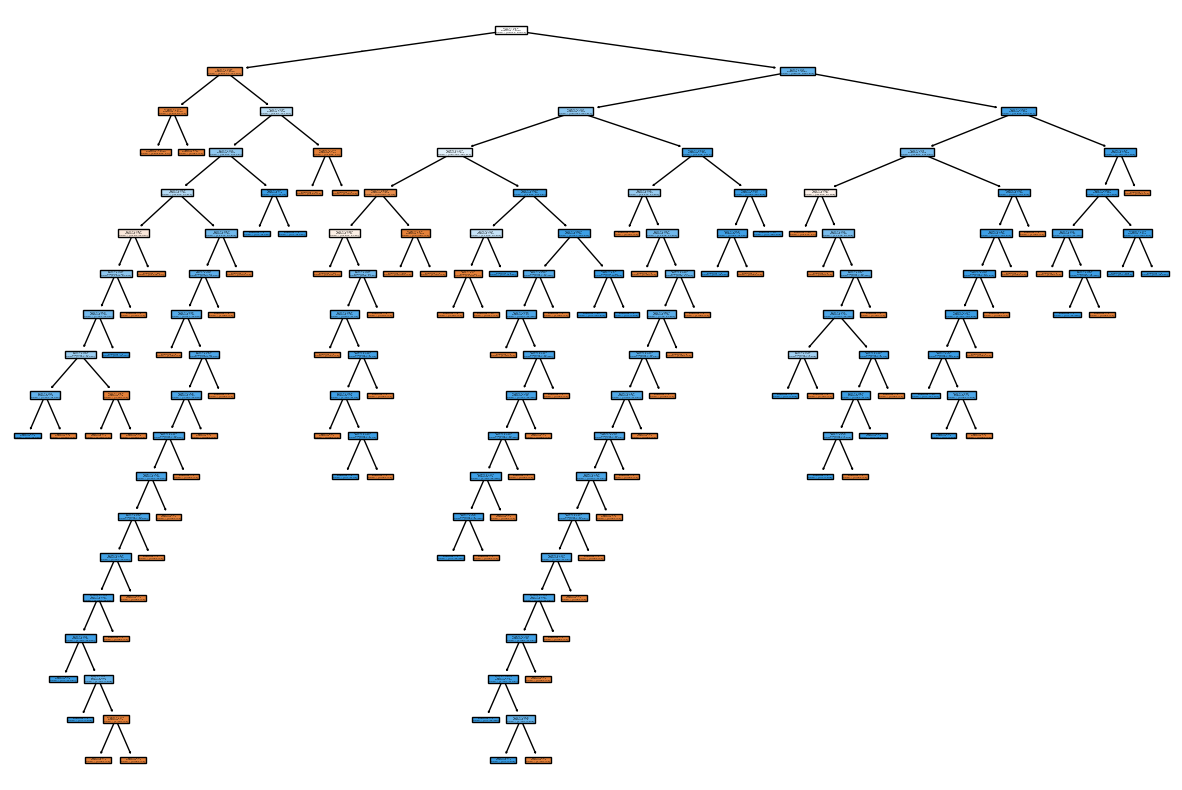

In [ ]:
# visualized the trainning tree
from sklearn import tree
plt.figure(figsize=(15,10))
tree.plot_tree(tree_clas, filled=True);

In [ ]:
feature_names = list(X_train.columns)
print(
    tree.export_text(
        tree_clas,    # specify the model
        feature_names=feature_names,    # specify the feature names
        show_weights=True    # specify whether or not to show the weights associated with the model
    )
)

|--- Income <= 92.50
|   |--- CCAvg <= 2.95
|   |   |--- City_Redlands <= 0.50
|   |   |   |--- weights: [1526.00, 0.00] class: 0
|   |   |--- City_Redlands >  0.50
|   |   |   |--- weights: [6.08, 0.00] class: 0
|   |--- CCAvg >  2.95
|   |   |--- CCAvg <= 3.95
|   |   |   |--- CD_Account <= 0.50
|   |   |   |   |--- Income <= 81.50
|   |   |   |   |   |--- Experience <= 18.50
|   |   |   |   |   |   |--- CCAvg <= 3.55
|   |   |   |   |   |   |   |--- Age <= 42.00
|   |   |   |   |   |   |   |   |--- Age <= 37.50
|   |   |   |   |   |   |   |   |   |--- Family <= 3.50
|   |   |   |   |   |   |   |   |   |   |--- weights: [0.00, 15.62] class: 1
|   |   |   |   |   |   |   |   |   |--- Family >  3.50
|   |   |   |   |   |   |   |   |   |   |--- weights: [3.32, 0.00] class: 0
|   |   |   |   |   |   |   |   |--- Age >  37.50
|   |   |   |   |   |   |   |   |   |--- Age <= 39.50
|   |   |   |   |   |   |   |   |   |   |--- weights: [1.11, 0.00] class: 0
|   |   |   |   |   |   |   |   |  

/tmp/ipython-input-2706265528.py:17: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  plot.set_xticklabels(plot.get_xticklabels(), rotation=90)


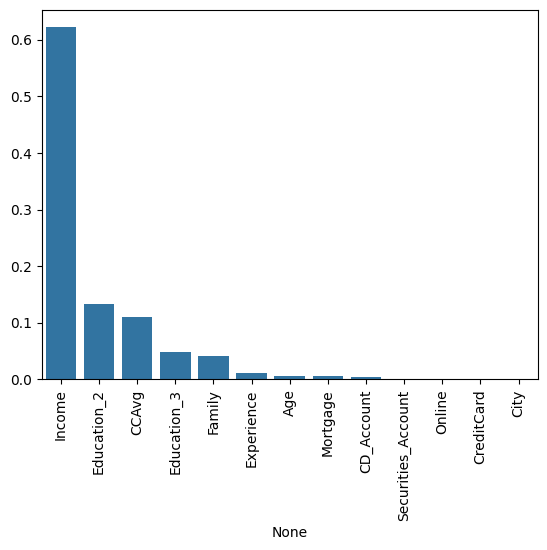

In [ ]:
# get the feature importance
feature_importances = pd.Series(tree_clas.feature_importances_, index=X.columns)
importances = {}
# agregates the cities and aeducation to be able of plot each feature
for item, key in feature_importances.items():
  if str.startswith(item, 'City'):
    importances['City'] = key
  else:
    importances[item] = key
# transform the importance dic into Pandas series so we can plot it
importances = pd.Series(importances)
# sort the values for better visualization
importances = importances.sort_values(ascending=False)

#plot the series and adjust the lables
plot = sns.barplot(x=importances.index, y=importances.values)
plot.set_xticklabels(plot.get_xticklabels(), rotation=90)
plt.show()

Observations

---

*   Seems the most important feature is the Income, then CCAvg and Family and Education
*   Tee tree is not very complex, but is large,need to see if we can make it better




### Model Evaluation Criterion

In [ ]:
def evaluate_tree(y, prediction):
  # scoring the tree.
  recall =     recall_score(y, prediction)
  acc =        accuracy_score(y, prediction)
  precision =  precision_score(y, prediction)
  f1 =         f1_score(y, prediction)

  # printing the results.
  print(f'Recall: {recall * 100}%')
  print(f'Accuracy: {acc * 100 }%')
  print(f'Precision: {precision * 100}%')
  print(f'F1: {f1 * 100}%')

  confusion_matrix_prediction_train = confusion_matrix(y, prediction)
  #show hitmap of the confustion matrix
  print(confusion_matrix_prediction_train)


Test tree

---



In [ ]:
# scoring the tree.
evaluate_tree(y_train, prediction_train)

Recall: 100.0%
Accuracy: 100.0%
Precision: 100.0%
F1: 100.0%
[[3616    0]
 [   0  384]]


Prediction tree

---



In [ ]:
# scoring the tree.
evaluate_tree(y_test, prediction_test)

Recall: 92.70833333333334%
Accuracy: 98.1%
Precision: 88.11881188118812%
F1: 90.35532994923858%
[[892  12]
 [  7  89]]


Observations:

---
*   The Performance of the test is very good with 90% in the F1 score.But the diff between the score is 10%.
*   We have 9 wrong predictions, and we need to try to minimize them.
*   also, a 100% test training says that we are seeing the noise in the data.




## Model Performance Improvement

Pre-prunning tree

---



In [ ]:
# Creation of depths to pre-prunning
max_depth_values = np.arange(2, 11, 2)

best_depth = max_depth_values[0]
best_f1 =  -1

for max_depth in max_depth_values:
  temp_tree = DecisionTreeClassifier(max_depth=max_depth, random_state=RS, class_weight='balanced')
  temp_tree.fit(X_train, y_train)
  temp_prediction_train = temp_tree.predict(X_train)
  temp_prediction_test = temp_tree.predict(X_test)

  f1_train = f1_score(y_train, temp_prediction_train)
  f1_test = f1_score(y_test, temp_prediction_test)

  print(f'Max depth: {max_depth}')
  print(f'F1 train: {f1_train}')
  print(f'F1 test: {f1_test}')

  if f1_test > best_f1:
    best_f1 = f1_test
    best_depth = max_depth

  print('\n')

print(f'Best depth: {best_depth}')

Max depth: 2
F1 train: 0.4758364312267658
F1 test: 0.46715328467153283


Max depth: 4
F1 train: 0.8109289617486338
F1 test: 0.773109243697479


Max depth: 6
F1 train: 0.89198606271777
F1 test: 0.8251121076233184


Max depth: 8
F1 train: 0.9400244798041616
F1 test: 0.8625592417061612


Max depth: 10
F1 train: 0.9746192893401016
F1 test: 0.8955223880597015


Best depth: 10


we check the performance of different depths in the tree so we can define the best parameter for the pre-pruning creation

In [ ]:
#create the Tree using the max_depth and then traaing it
tree_pre_prun = DecisionTreeClassifier(max_depth=best_depth, random_state=RS, class_weight='balanced')
tree_pre_prun.fit(X_train, y_train)

#predict the data
pre_prun_prediction_train = tree_pre_prun.predict(X_train)
pre_prun_prediction_test = tree_pre_prun.predict(X_test)
print('-------TRAIN------')
evaluate_tree(y_train, pre_prun_prediction_train)
print('\n-------TEST-----')
evaluate_tree(y_test, pre_prun_prediction_test)

-------TRAIN------
Recall: 100.0%
Accuracy: 99.5%
Precision: 95.04950495049505%
F1: 97.46192893401016%
[[3596   20]
 [   0  384]]

-------TEST-----
Recall: 93.75%
Accuracy: 97.89999999999999%
Precision: 85.71428571428571%
F1: 89.55223880597015%
[[889  15]
 [  6  90]]


Observation

---

in this case we have better Precision and F1

Post Prunning tree

---



In [ ]:
# get the cost complexity of a tree for our data
temp_tree = DecisionTreeClassifier(random_state=RS, class_weight='balanced')
temp_tree.fit(X_train, y_train)

path = temp_tree.cost_complexity_pruning_path(X_train, y_train)
cost_complexity = abs(path.ccp_alphas)
cost_complexity

array([0.00000000e+00, 9.21092111e-20, 6.87748776e-18, 8.90389041e-18,
       2.51534904e-17, 2.94902991e-17, 7.41594286e-17, 2.38900591e-16,
       3.12066007e-16, 6.80380039e-16, 1.35869565e-04, 1.37578616e-04,
       1.38081395e-04, 2.44140625e-04, 2.50000000e-04, 2.57050529e-04,
       2.62448904e-04, 2.62605042e-04, 2.69701823e-04, 2.72415940e-04,
       3.68738324e-04, 4.64747356e-04, 4.85515740e-04, 6.04114393e-04,
       6.07905983e-04, 6.37218045e-04, 7.85395418e-04, 8.91887455e-04,
       9.34625819e-04, 9.70496894e-04, 1.05748663e-03, 1.59687579e-03,
       1.64797770e-03, 1.72583492e-03, 2.19500445e-03, 2.24799856e-03,
       2.60206507e-03, 2.76237065e-03, 4.91077764e-03, 5.04029951e-03,
       5.07912152e-03, 5.85004835e-03, 2.80255399e-02, 3.66224919e-02,
       2.86546592e-01])

In [ ]:
# create a tree for each of the complexity results
trees_post_prune = []
only_one_node = []
for i, complexity in enumerate(cost_complexity):
  #creating a tree of the specific complexity
  temp_tree = DecisionTreeClassifier(random_state=RS, ccp_alpha=complexity, class_weight='balanced')

  #training the tree
  temp_tree.fit(X_train, y_train)
  # if tree is deeper than 1 ( root ) adding it to the final array
  if temp_tree.tree_.node_count > 1:
    trees_post_prune.append(temp_tree)
  else:
    only_one_node = i-1 if i > 0 else i
# removing object in index only_one_node
cost_complexity = np.delete(cost_complexity, only_one_node)


In [ ]:
# looping each tree in post prune array and executing the socore
train_scores = []
test_scores = []
for tree in trees_post_prune:
  # predict using post-prune tree
  temp_prediction_train = tree.predict(X_train)
  temp_prediction_test = tree.predict(X_test)
  # saving f1 score for each tree in both data sets
  train_scores.append(f1_score(y_train, temp_prediction_train))
  test_scores.append(f1_score(y_test, temp_prediction_test))

In [ ]:
cost_complexity


array([0.00000000e+00, 9.21092111e-20, 6.87748776e-18, 8.90389041e-18,
       2.51534904e-17, 2.94902991e-17, 7.41594286e-17, 2.38900591e-16,
       3.12066007e-16, 6.80380039e-16, 1.35869565e-04, 1.37578616e-04,
       1.38081395e-04, 2.44140625e-04, 2.50000000e-04, 2.57050529e-04,
       2.62448904e-04, 2.62605042e-04, 2.69701823e-04, 2.72415940e-04,
       3.68738324e-04, 4.64747356e-04, 4.85515740e-04, 6.04114393e-04,
       6.07905983e-04, 6.37218045e-04, 7.85395418e-04, 8.91887455e-04,
       9.34625819e-04, 9.70496894e-04, 1.05748663e-03, 1.59687579e-03,
       1.64797770e-03, 1.72583492e-03, 2.19500445e-03, 2.24799856e-03,
       2.60206507e-03, 2.76237065e-03, 4.91077764e-03, 5.04029951e-03,
       5.07912152e-03, 5.85004835e-03, 2.80255399e-02, 2.86546592e-01])

In [ ]:
train_scores

[1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 0.9986996098829649,
 0.9974025974025974,
 0.9961089494163424,
 0.9833546734955185,
 0.9721518987341772,
 0.9660377358490566,
 0.964824120603015,
 0.9612015018773467,
 0.9576059850374065,
 0.9564134495641345,
 0.9516728624535316,
 0.9493201483312732,
 0.9458128078817734,
 0.9388753056234719,
 0.9331713244228432,
 0.9264173703256936,
 0.9230769230769231,
 0.9175627240143369,
 0.9131985731272295,
 0.89198606271777,
 0.8868360277136259,
 0.8777142857142857,
 0.8687782805429864,
 0.8600223964165733,
 0.8458149779735683,
 0.8118393234672304,
 0.7950310559006211,
 0.7950310559006211,
 0.8008474576271186,
 0.7582748244734202,
 0.7262247838616714,
 0.7262247838616714,
 0.8,
 0.49591280653950953]

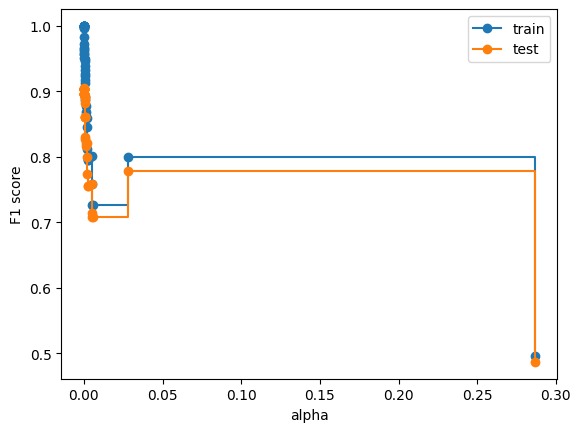

In [ ]:
# visualize the f1 scores of the train X test with the cost complexity to get the elbow
fig, ax = plt.subplots()
ax.plot(cost_complexity, train_scores,marker="o",drawstyle='steps-post', label='train')
ax.plot(cost_complexity, test_scores,marker="o",drawstyle='steps-post', label='test')
ax.set_xlabel("alpha")
ax.set_ylabel("F1 score")
ax.legend()
plt.show()

In [ ]:

best_score = Series(test_scores).sort_values(ascending=False).index[0]

best_complexity =  cost_complexity[best_score]
print(f'Best complexity: {best_complexity} at index {best_score} with score {test_scores[best_score]*100}')
post_prune_tree = trees_post_prune[best_score]
post_prun_prediction_test = post_prune_tree.predict(X_test)
post_prun_prediction_train = post_prune_tree.predict(X_train)

print('-------TRAIN------')
evaluate_tree(y_train, post_prun_prediction_train)
print('\n-------TEST-----')
evaluate_tree(y_test, post_prun_prediction_test)


Best complexity: 0.00024414062499999761 at index 13 with score 90.45226130653266
-------TRAIN------
Recall: 100.0%
Accuracy: 99.675%
Precision: 96.72544080604534%
F1: 98.33546734955185%
[[3603   13]
 [   0  384]]

-------TEST-----
Recall: 93.75%
Accuracy: 98.1%
Precision: 87.37864077669903%
F1: 90.45226130653266%
[[891  13]
 [  6  90]]


## Model Performance Comparison and Final Model Selection

In [ ]:
print('\n-------Not tinned TEST-----')
evaluate_tree(y_test, prediction_test)

print('\n-------Pre Prun TEST-----')
evaluate_tree(y_test, pre_prun_prediction_test)

print('\n-------Post Prun TEST-----')
evaluate_tree(y_test, post_prun_prediction_test)


-------Not tinned TEST-----
Recall: 92.70833333333334%
Accuracy: 98.1%
Precision: 88.11881188118812%
F1: 90.35532994923858%
[[892  12]
 [  7  89]]

-------Pre Prun TEST-----
Recall: 93.75%
Accuracy: 97.89999999999999%
Precision: 85.71428571428571%
F1: 89.55223880597015%
[[889  15]
 [  6  90]]

-------Post Prun TEST-----
Recall: 93.75%
Accuracy: 98.1%
Precision: 87.37864077669903%
F1: 90.45226130653266%
[[891  13]
 [  6  90]]


Observations

---


Base on the different scores of each selected Model we can say that the one that has the best score is the post-Prune Tree post_prun_prediction_test




/tmp/ipython-input-3755230398.py:17: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  plot.set_xticklabels(plot.get_xticklabels(), rotation=90)


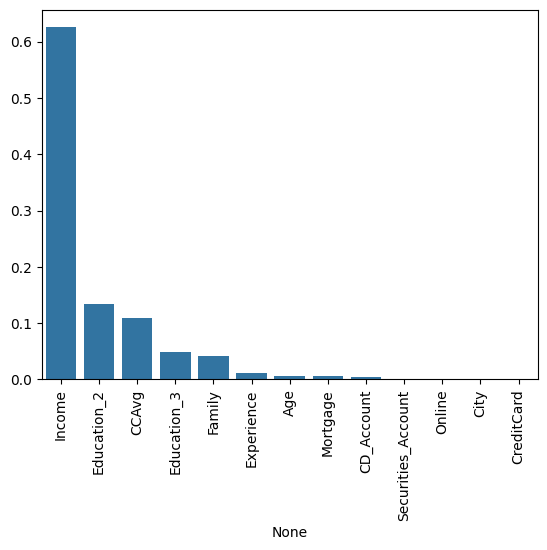

In [ ]:
# get the feature importance
feature_importances = pd.Series(post_prune_tree.feature_importances_, index=X.columns)
importances = {}
# agregates the cities and aeducation to be able of plot each feature
for item, key in feature_importances.items():
  if str.startswith(item, 'City'):
    importances['City'] = key
  else:
    importances[item] = key
# transform the importance dic into Pandas series so we can plot it
importances = pd.Series(importances)
# sort the values for better visualization
importances = importances.sort_values(ascending=False)

#plot the series and adjust the lables
plot = sns.barplot(x=importances.index, y=importances.values)
plot.set_xticklabels(plot.get_xticklabels(), rotation=90)
plt.show()

Observations

---

* WE can see the top features are Income Education 2 and ccAvg
* The Income is the most important feature
* Education itself is also important


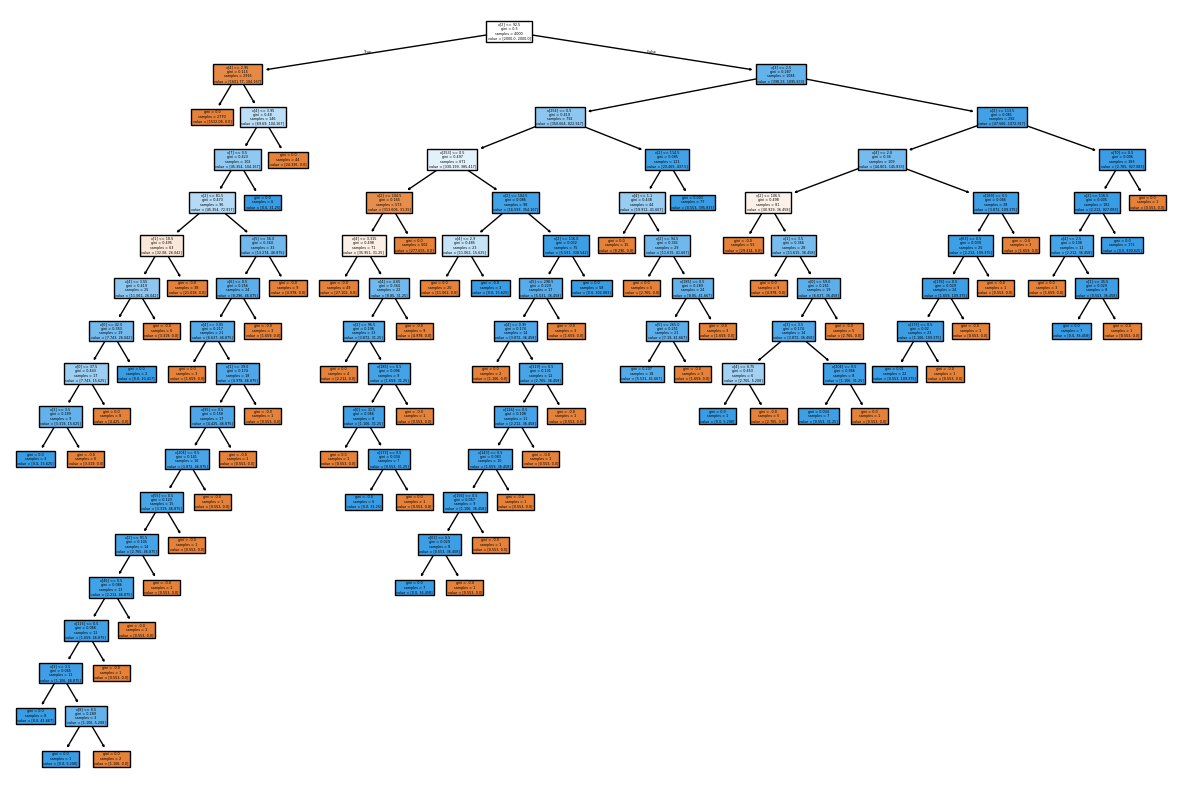

In [ ]:
from sklearn import tree
plt.figure(figsize=(15,10))
tree.plot_tree(post_prune_tree, filled=True);

Observations

---
We can see the new tree is simpler than the original one and it has better scores.


In [ ]:
feature_names = list(X_train.columns)
print(
    tree.export_text(
        post_prune_tree,    # specify the model
        feature_names=feature_names,    # specify the feature names
        show_weights=True    # specify whether or not to show the weights associated with the model
    )
)

|--- Income <= 92.50
|   |--- CCAvg <= 2.95
|   |   |--- weights: [1532.08, 0.00] class: 0
|   |--- CCAvg >  2.95
|   |   |--- CCAvg <= 3.95
|   |   |   |--- CD_Account <= 0.50
|   |   |   |   |--- Income <= 81.50
|   |   |   |   |   |--- Experience <= 18.50
|   |   |   |   |   |   |--- CCAvg <= 3.55
|   |   |   |   |   |   |   |--- Age <= 42.00
|   |   |   |   |   |   |   |   |--- Age <= 37.50
|   |   |   |   |   |   |   |   |   |--- Family <= 3.50
|   |   |   |   |   |   |   |   |   |   |--- weights: [0.00, 15.62] class: 1
|   |   |   |   |   |   |   |   |   |--- Family >  3.50
|   |   |   |   |   |   |   |   |   |   |--- weights: [3.32, 0.00] class: 0
|   |   |   |   |   |   |   |   |--- Age >  37.50
|   |   |   |   |   |   |   |   |   |--- weights: [4.42, 0.00] class: 0
|   |   |   |   |   |   |   |--- Age >  42.00
|   |   |   |   |   |   |   |   |--- weights: [0.00, 10.42] class: 1
|   |   |   |   |   |   |--- CCAvg >  3.55
|   |   |   |   |   |   |   |--- weights: [3.32, 0.00] cl

## Actionable Insights and Business Recommendations


* The bank should focus its targeting primarily on customers with high Income and high CCAvg.
* The type of Education also segments the market effectively.
* People with lower educatin are not the best to offer a Loano
* Aspects like city, security account, credit card are not important to clasify, even when the tree shows that high-income people from Emeryville are not propbably taking a personal Loan


Observations

---


* Target the marketing campaign to customers with incomes above 92,500 dollars and average balances greater than 2,900 dollars.
* Try not to focus the campaign on any specific city, especially if the customer has an income above 113,500 dollars and is from Emeryville.
* People with lower incomes tend to require multiple variables to qualify for a loan, but those earning less than $92,500 who have a CD_Account tend to request loans. Therefore, the marketing department can focus a campaign promoting CD_Account to that segment.
* You can target people by age, but they need to meet specific criteria: they should be low-income customers who spend heavily on credit cards but do not have a CD_Account. In this segment, younger customers with small families tend to take loans, and those older than 42 also tend to take loans.

___